**Live Deployment Link:** [Open the Titanic Passenger Survival Prediction System app](https://ml-lab-assignment-gwnyxabzax8nwfaueusdeb.streamlit.app/)

**Name:** Mubashir Ali  
**Registration No.:** Fa24-bse-140

# Titanic Passenger Survival Prediction System

## 1. Import Libraries

In [1]:
import pandas as pd
import pickle
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## 2. Load Data

Use the supplied 100-row Titanic teaching dataset. The four input attributes are PClass, Gender, Sibling and Embarked.

Keep this notebook and its sample-data.csv in the same folder.

In [2]:
data = pd.read_csv("sample-data.csv")
print(data.head())
print("Rows:", len(data))

   PClass  Gender Sibling     Embarked Survived
0   Third    Male     One  Southampton       No
1  Second  Female    Zero  Southampton      Yes
2   Third    Male    Zero  Southampton       No
3   Third  Female   Three  Southampton      Yes
4   Third    Male    Zero   Queenstown       No
Rows: 100


## 3. Understand and Clean Data

In [3]:
print(data.isnull().sum())
print(data['Survived'].value_counts())
data = data.dropna().copy()

PClass      0
Gender      0
Sibling     0
Embarked    0
Survived    0
dtype: int64
Survived
No     50
Yes    50
Name: count, dtype: int64


## 4. Select Four Input Attributes

In [4]:
features = ['PClass', 'Gender', 'Sibling', 'Embarked']
target = 'Survived'
data = data[features + [target]]

## 5. Label Encoding

In [5]:
encoded = data.copy()
encoders = {}

for column in data.columns:
    encoder = LabelEncoder()
    encoded[column] = encoder.fit_transform(data[column])
    encoders[column] = encoder

encoded.to_csv("sample-data-encoded.csv", index=False)
output_data = data.copy()
output_data[target] = encoded[target]
output_data.to_csv("sample-data-encoded-output.csv", index=False)
output_data = data.copy()
output_data[target] = encoded[target]
output_data.to_csv("sample-data-encoded-output.csv", index=False)
print(encoded.head())

   PClass  Gender  Sibling  Embarked  Survived
0       2       1        0         2         0
1       1       0        3         2         1
2       2       1        3         2         0
3       2       0        1         2         1
4       2       1        3         1         0


## 6. Training Phase

Use 80% of the data for training and 20% for testing.

In [6]:
training, testing = train_test_split(
    encoded, test_size=0.2, random_state=0, shuffle=False
)

training.to_csv("training-data-encoded.csv", index=False)
testing.to_csv("testing-data-encoded.csv", index=False)

X_train = training[features]
y_train = training[target]
X_test = testing[features]
y_test = testing[target]

model = SVC(gamma="auto", random_state=0)
model.fit(X_train, y_train)

with open('svc_trained_model.pkl', "wb") as file:
    pickle.dump(model, file)

## 7. Testing Phase

Accuracy: 0.8
              precision    recall  f1-score   support

          No       0.71      1.00      0.83        10
         Yes       1.00      0.60      0.75        10

    accuracy                           0.80        20
   macro avg       0.86      0.80      0.79        20
weighted avg       0.86      0.80      0.79        20



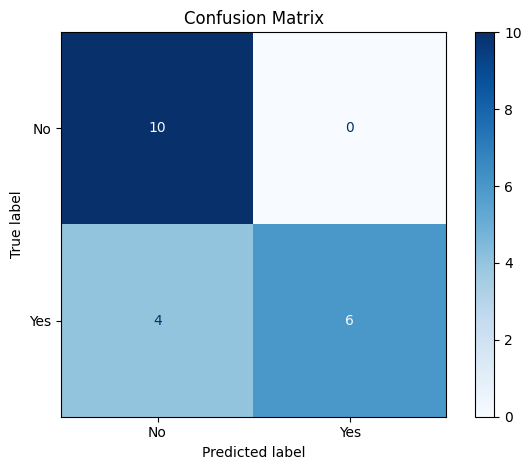

In [7]:
with open('svc_trained_model.pkl', "rb") as file:
    model = pickle.load(file)

predictions = model.predict(X_test)
accuracy = accuracy_score(y_test, predictions)
print("Accuracy:", round(accuracy, 2))
print(classification_report(y_test, predictions, target_names=encoders[target].classes_))

results = testing.copy()
results["Predictions"] = predictions
results.to_csv("model-predictions.csv", index=False)

ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, display_labels=encoders[target].classes_, cmap="Blues"
)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

## 8. Application Phase

Edit the example values below to test another passenger or patient.

In [8]:
example = pd.DataFrame([['First', 'Male', 'Zero', 'Queenstown']], columns=features)
example_encoded = example.copy()

for column in features:
    example_encoded[column] = encoders[column].transform(example[column])

prediction = model.predict(example_encoded)
print("Prediction:", encoders[target].inverse_transform(prediction)[0])

Prediction: Yes


## 9. Feedback Phase

Ask users to review the predictions. These are suggested improvements, not collected user feedback.

In [9]:
improvements = ['Collect a larger Titanic dataset.', 'Compare SVC with other classifiers.']

for item in improvements:
    print(item)

Collect a larger Titanic dataset.
Compare SVC with other classifiers.


## 10. Cloud Deployment

**Name:** Mubashir Ali  
**Registration No.:** Fa24-bse-140

**GitHub repository:** [https://github.com/thismubashir/ML-LAB-Assignment](https://github.com/thismubashir/ML-LAB-Assignment)  
**Branch:** main  
**Streamlit main file:** `app.py`

### Deployed Streamlit Apps

| App | Streamlit link |
| --- | --- |
| Titanic | [Open app](https://ml-lab-assignment-gwnyxabzax8nwfaueusdeb.streamlit.app/) |
| Heart Disease | [Open app](https://ml-lab-assignment-tbdhtsrxjgmpyfxc2vxktl.streamlit.app/) |